<a href="https://colab.research.google.com/github/jinho1017-eng/changwon-bus-analysis/blob/main/changwon_bus_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. 데이터 기본 확인**

기본 라이브러리 불러오기와 한글 폰트 설정

In [16]:
!apt-get -qq install fonts-nanum

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)

sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

print("라이브러리 불러오기 및 한글 폰트 설정 완료")

라이브러리 불러오기 및 한글 폰트 설정 완료


창원시 시내버스 탑승인원 엑셀 파일 지정

In [17]:
import glob

# Colab 왼쪽 파일 창에 업로드한 엑셀 파일을 자동으로 찾기
file_name = glob.glob("*.xlsx")[0]
print("사용할 파일명:", file_name)

사용할 파일명: 경상남도 창원시_시내버스 탑승인원_20250605.xlsx


엑셀 시트 목록 확인

In [18]:
excel_file = pd.ExcelFile(file_name)
sheet_names = excel_file.sheet_names

print("전체 시트 개수:", len(sheet_names))
print("시트 목록:")
for sheet in sheet_names:
    print("-", sheet)

전체 시트 개수: 145
시트 목록:
- 정류장별 인원(25.05.19.~05.25.)
- 10(노선별인원→)
- 11
- 12
- 13
- 14
- 15
- 17
- 19
- 20
- 21
- 22
- 23
- 24
- 27
- 30
- 31
- 32
- 33
- 34
- 35
- 36
- 37
- 40
- 41
- 42
- 44
- 45
- 46
- 49
- 50
- 51
- 53
- 54
- 55
- 60
- 61
- 62
- 64
- 70
- 71
- 72
- 72-1
- 73
- 73-1
- 74
- 74-1
- 75
- 75-1
- 76
- 77
- 77-1
- 78
- 80
- 100
- 101
- 102
- 103
- 105
- 106
- 107
- 108
- 109
- 110
- 111
- 113
- 114
- 115
- 116
- 122
- 150
- 151
- 152
- 155
- 156
- 160
- 162
- 163
- 164
- 212
- 213
- 214
- 215
- 216
- 219
- 220
- 221
- 222
- 223
- 224
- 225
- 240
- 250
- 251
- 253
- 254
- 256
- 257
- 258
- 259
- 260
- 262
- 263
- 264
- 270
- 271
- 272
- 273
- 277
- 301
- 302
- 303
- 305
- 306
- 307
- 309
- 315
- 317
- 325
- 361
- 510
- 511
- 530
- 540
- 710
- 720
- 730
- 740
- 770
- 901
- 990
- 995
- 995-1
- 996
- 998
- 999
- 3000
- 3001
- 3002
- 3003
- 3004
- 3005
- 3006
- 5000
- 6000


정류장별 시트와 노선별 시트 구분

In [19]:
station_sheet = sheet_names[0]
route_sheets = sheet_names[1:]

print("정류장별 인원 시트:", station_sheet)
print("노선별 시트 개수:", len(route_sheets))
print("노선별 시트 예시:", route_sheets[:10])

정류장별 인원 시트: 정류장별 인원(25.05.19.~05.25.)
노선별 시트 개수: 144
노선별 시트 예시: ['10(노선별인원→)', '11', '12', '13', '14', '15', '17', '19', '20', '21']


정류장별 데이터 기본 확인

In [20]:
station_df = pd.read_excel(file_name, sheet_name=station_sheet)

station_df.columns = station_df.columns.astype(str).str.strip()

print("===== 정류장별 데이터 기본 확인 =====")

print("정류장별 데이터 크기(행, 열):", station_df.shape)
print("정류장별 행 개수:", station_df.shape[0])
print("정류장별 열 개수:", station_df.shape[1])

print("\n정류장별 데이터 컬럼명:")
print(station_df.columns.tolist())

print("\n정류장별 데이터 상위 5개:")
display(station_df.head())

print("\n정류장별 데이터 변수 타입:")
display(station_df.dtypes)

print("\n정류장별 데이터 기초통계량:")
display(station_df.describe(include="all"))

===== 정류장별 데이터 기본 확인 =====
정류장별 데이터 크기(행, 열): (3054, 4)
정류장별 행 개수: 3054
정류장별 열 개수: 4

정류장별 데이터 컬럼명:
['정류장코드', '정류장명', '비환승', '환승']

정류장별 데이터 상위 5개:


,정류장코드,정류장명,비환승,환승
0,4828293,(주)HND로지스틱스,0,0
1,4831360,(주)거보,0,0
2,4832080,(주)거보,0,0
3,4828153,(주)대륜기업,0,0
4,4828033,(주)세웅전기,0,0



정류장별 데이터 변수 타입:


,0
정류장코드,int64
정류장명,object
비환승,int64
환승,int64



정류장별 데이터 기초통계량:


,정류장코드,정류장명,비환승,환승
count,3.054000e+03,3054,3054.000000,3054.000000
unique,NaN,1600,NaN,NaN
top,NaN,진북면행정복지센터,NaN,NaN
freq,NaN,7,NaN,NaN
mean,5.068228e+06,NaN,402.769483,60.233137
std,1.007728e+06,NaN,1149.981240,291.867079
min,4.800012e+06,NaN,0.000000,0.000000
25%,4.809754e+06,NaN,0.000000,0.000000
50%,4.819437e+06,NaN,22.000000,0.000000
75%,4.826952e+06,NaN,305.000000,11.000000


노선별,시간대별 데이터 통합

In [21]:

route_data_list = []
error_sheets = []

for sheet in route_sheets:
    try:
        temp = pd.read_excel(file_name, sheet_name=sheet)
        temp.columns = temp.columns.astype(str).str.strip()

        time_cols = [c for c in temp.columns if "시간" in c]
        non_transfer_cols = [c for c in temp.columns if "비환승" in c]
        transfer_cols = [c for c in temp.columns if "환승" in c and "비환승" not in c]

        if len(time_cols) == 0 or len(non_transfer_cols) == 0 or len(transfer_cols) == 0:
            error_sheets.append((sheet, temp.columns.tolist()))
            continue

        time_col = time_cols[0]
        non_transfer_col = non_transfer_cols[0]
        transfer_col = transfer_cols[0]

        temp = temp[[time_col, non_transfer_col, transfer_col]].copy()
        temp.columns = ["시간대", "비환승", "환승"]

        temp["노선번호"] = str(sheet).split("(")[0].strip()

        route_data_list.append(temp)

    except Exception as e:
        error_sheets.append((sheet, str(e)))

route_df = pd.concat(route_data_list, ignore_index=True)

print("===== 노선별·시간대별 데이터 통합 결과 =====")
print("통합된 데이터 크기(행, 열):", route_df.shape)
print("통합된 행 개수:", route_df.shape[0])
print("통합된 열 개수:", route_df.shape[1])
print("통합된 노선 개수:", route_df["노선번호"].nunique())
print("시간대 개수:", route_df["시간대"].nunique())

print("\n오류 발생 시트 개수:", len(error_sheets))
if len(error_sheets) > 0:
    print("오류 발생 시트 예시:")
    print(error_sheets[:5])

print("\n노선별 통합 데이터 상위 5개:")
display(route_df.head())

print("\n노선별 통합 데이터 변수 타입:")
display(route_df.dtypes)

print("\n노선별 통합 데이터 기초통계량:")
display(route_df.describe(include="all"))

===== 노선별·시간대별 데이터 통합 결과 =====
통합된 데이터 크기(행, 열): (3456, 4)
통합된 행 개수: 3456
통합된 열 개수: 4
통합된 노선 개수: 144
시간대 개수: 24

오류 발생 시트 개수: 0

노선별 통합 데이터 상위 5개:


,시간대,비환승,환승,노선번호
0,00:00~00:59,0,0,10
1,01:00~01:59,0,0,10
2,02:00~02:59,0,0,10
3,03:00~03:59,0,0,10
4,04:00~04:59,0,0,10



노선별 통합 데이터 변수 타입:


,0
시간대,object
비환승,int64
환승,int64
노선번호,object



노선별 통합 데이터 기초통계량:


,시간대,비환승,환승,노선번호
count,3456,3456.000000,3456.000000,3456
unique,24,NaN,NaN,144
top,00:00~00:59,NaN,NaN,10
freq,144,NaN,NaN,24
mean,NaN,324.153067,48.610243,NaN
std,NaN,622.135482,95.883199,NaN
min,NaN,0.000000,0.000000,NaN
25%,NaN,0.000000,0.000000,NaN
50%,NaN,59.000000,9.000000,NaN
75%,NaN,357.000000,48.000000,NaN


숫자형 변수 변환

In [22]:
route_df["비환승"] = pd.to_numeric(route_df["비환승"], errors="coerce")
route_df["환승"] = pd.to_numeric(route_df["환승"], errors="coerce")

print("===== 숫자형 변환 후 변수 타입 =====")
display(route_df.dtypes)

print("\n숫자형 변환 후 상위 5개:")
display(route_df.head())

===== 숫자형 변환 후 변수 타입 =====


,0
시간대,object
비환승,int64
환승,int64
노선번호,object



숫자형 변환 후 상위 5개:


,시간대,비환승,환승,노선번호
0,00:00~00:59,0,0,10
1,01:00~01:59,0,0,10
2,02:00~02:59,0,0,10
3,03:00~03:59,0,0,10
4,04:00~04:59,0,0,10


파생 변수 생성

In [23]:

route_df["총탑승인원"] = route_df["비환승"] + route_df["환승"]

route_df["환승비율"] = np.where(
    route_df["총탑승인원"] == 0,
    0,
    route_df["환승"] / route_df["총탑승인원"]
)

print("===== 파생 변수 생성 후 데이터 확인 =====")

print("데이터 크기(행, 열):", route_df.shape)
print("전체 행 개수:", route_df.shape[0])
print("전체 열 개수:", route_df.shape[1])

print("\n상위 5개 행:")
display(route_df.head())

print("\n변수 타입:")
display(route_df.dtypes)

print("\n기초통계량:")
display(route_df.describe(include="all"))

===== 파생 변수 생성 후 데이터 확인 =====
데이터 크기(행, 열): (3456, 6)
전체 행 개수: 3456
전체 열 개수: 6

상위 5개 행:


,시간대,비환승,환승,노선번호,총탑승인원,환승비율
0,00:00~00:59,0,0,10,0,0.0
1,01:00~01:59,0,0,10,0,0.0
2,02:00~02:59,0,0,10,0,0.0
3,03:00~03:59,0,0,10,0,0.0
4,04:00~04:59,0,0,10,0,0.0



변수 타입:


,0
시간대,object
비환승,int64
환승,int64
노선번호,object
총탑승인원,int64
환승비율,float64



기초통계량:


,시간대,비환승,환승,노선번호,총탑승인원,환승비율
count,3456,3456.000000,3456.000000,3456,3456.000000,3456.000000
unique,24,NaN,NaN,144,NaN,NaN
top,00:00~00:59,NaN,NaN,10,NaN,NaN
freq,144,NaN,NaN,24,NaN,NaN
mean,NaN,324.153067,48.610243,NaN,372.763310,0.099205
std,NaN,622.135482,95.883199,NaN,713.886557,0.110937
min,NaN,0.000000,0.000000,NaN,0.000000,0.000000
25%,NaN,0.000000,0.000000,NaN,0.000000,0.000000
50%,NaN,59.000000,9.000000,NaN,68.500000,0.091643
75%,NaN,357.000000,48.000000,NaN,409.000000,0.147240


전체 개수 확인

In [24]:

print("===== 전체 데이터 개수 확인 =====")

print("노선별·시간대별 데이터 전체 크기(행, 열):", route_df.shape)
print("전체 행 개수:", route_df.shape[0])
print("전체 열 개수:", route_df.shape[1])

print("\n전체 노선 개수:", route_df["노선번호"].nunique())
print("전체 시간대 개수:", route_df["시간대"].nunique())

print("\n노선번호 목록:")
print(sorted(route_df["노선번호"].unique()))

print("\n시간대 목록:")
print(route_df["시간대"].unique())

===== 전체 데이터 개수 확인 =====
노선별·시간대별 데이터 전체 크기(행, 열): (3456, 6)
전체 행 개수: 3456
전체 열 개수: 6

전체 노선 개수: 144
전체 시간대 개수: 24

노선번호 목록:
['10', '100', '101', '102', '103', '105', '106', '107', '108', '109', '11', '110', '111', '113', '114', '115', '116', '12', '122', '13', '14', '15', '150', '151', '152', '155', '156', '160', '162', '163', '164', '17', '19', '20', '21', '212', '213', '214', '215', '216', '219', '22', '220', '221', '222', '223', '224', '225', '23', '24', '240', '250', '251', '253', '254', '256', '257', '258', '259', '260', '262', '263', '264', '27', '270', '271', '272', '273', '277', '30', '3000', '3001', '3002', '3003', '3004', '3005', '3006', '301', '302', '303', '305', '306', '307', '309', '31', '315', '317', '32', '325', '33', '34', '35', '36', '361', '37', '40', '41', '42', '44', '45', '46', '49', '50', '5000', '51', '510', '511', '53', '530', '54', '540', '55', '60', '6000', '61', '62', '64', '70', '71', '710', '72', '72-1', '720', '73', '73-1', '730', '74', '74-1', '740', '7

노선별, 시간대별  탑승 인원 확인




In [25]:

route_time_summary = route_df.groupby(["노선번호", "시간대"])[
    ["비환승", "환승", "총탑승인원"]
].sum().reset_index()

print("===== 노선별·시간대별 탑승 인원 확인 =====")

print("노선별·시간대별 데이터 크기(행, 열):", route_time_summary.shape)
print("전체 행 개수:", route_time_summary.shape[0])
print("전체 열 개수:", route_time_summary.shape[1])

print("\n전체 노선 개수:", route_time_summary["노선번호"].nunique())
print("전체 시간대 개수:", route_time_summary["시간대"].nunique())

print("\n노선별·시간대별 데이터 상위 50개:")
display(route_time_summary.head(50))

print("\n노선별 시간대 개수:")
display(route_time_summary["노선번호"].value_counts().sort_index())

===== 노선별·시간대별 탑승 인원 확인 =====
노선별·시간대별 데이터 크기(행, 열): (3456, 5)
전체 행 개수: 3456
전체 열 개수: 5

전체 노선 개수: 144
전체 시간대 개수: 24

노선별·시간대별 데이터 상위 50개:


,노선번호,시간대,비환승,환승,총탑승인원
0,10,00:00~00:59,0,0,0
1,10,01:00~01:59,0,0,0
2,10,02:00~02:59,0,0,0
3,10,03:00~03:59,0,0,0
4,10,04:00~04:59,0,0,0
5,10,05:00~05:59,0,0,0
6,10,06:00~06:59,252,24,276
7,10,07:00~07:59,245,40,285
8,10,08:00~08:59,401,65,466
9,10,09:00~09:59,259,37,296



노선별 시간대 개수:


,count
노선번호,
10,24
100,24
101,24
102,24
103,24
...,...
995,24
995-1,24
996,24


시간대별 전체 탑승 인원 확인

In [26]:

time_summary = route_df.groupby("시간대")[
    ["비환승", "환승", "총탑승인원"]
].sum().reset_index()

print("===== 시간대별 전체 탑승 인원 =====")

print("시간대별 데이터 크기(행, 열):", time_summary.shape)
print("전체 시간대 개수:", time_summary.shape[0])

display(time_summary)

===== 시간대별 전체 탑승 인원 =====
시간대별 데이터 크기(행, 열): (24, 4)
전체 시간대 개수: 24


,시간대,비환승,환승,총탑승인원
0,00:00~00:59,157,14,171
1,01:00~01:59,0,0,0
2,02:00~02:59,0,0,0
3,03:00~03:59,0,0,0
4,04:00~04:59,61,0,61
5,05:00~05:59,14061,1148,15209
6,06:00~06:59,36385,5602,41987
7,07:00~07:59,87391,11427,98818
8,08:00~08:59,90620,12896,103516
9,09:00~09:59,61890,10726,72616


**2. 결측값 & 이상값 처리**

변수별 결측값 수 및 비율 확인

In [27]:

print("===== 노선별·시간대별 데이터 결측값 확인 =====")

missing_count = route_df.isnull().sum()
missing_ratio = (route_df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({
    "결측값 수": missing_count,
    "결측값 비율(%)": missing_ratio
})

display(missing_table)

===== 노선별·시간대별 데이터 결측값 확인 =====


,결측값 수,결측값 비율(%)
시간대,0,0.0
비환승,0,0.0
환승,0,0.0
노선번호,0,0.0
총탑승인원,0,0.0
환승비율,0,0.0


정류장별 데이터 결측값 확인

In [28]:

print("===== 정류장별 데이터 결측값 확인 =====")

station_missing_count = station_df.isnull().sum()
station_missing_ratio = (station_df.isnull().mean() * 100).round(2)

station_missing_table = pd.DataFrame({
    "결측값 수": station_missing_count,
    "결측값 비율(%)": station_missing_ratio
})

display(station_missing_table)

===== 정류장별 데이터 결측값 확인 =====


,결측값 수,결측값 비율(%)
정류장코드,0,0.0
정류장명,0,0.0
비환승,0,0.0
환승,0,0.0


결측값 처리

In [29]:

before_rows = len(route_df)

route_df_clean = route_df.dropna(
    subset=["시간대", "비환승", "환승", "노선번호"]
).copy()

after_rows = len(route_df_clean)

print("결측값 처리 전 행 개수:", before_rows)
print("결측값 처리 후 행 개수:", after_rows)
print("제거된 행 개수:", before_rows - after_rows)

print("\n결측값 처리 후 결측값 확인:")
display(route_df_clean.isnull().sum())

결측값 처리 전 행 개수: 3456
결측값 처리 후 행 개수: 3456
제거된 행 개수: 0

결측값 처리 후 결측값 확인:


,0
시간대,0
비환승,0
환승,0
노선번호,0
총탑승인원,0
환승비율,0


총탑승인원, 환승 비율 다시 생성

In [30]:

route_df_clean["총탑승인원"] = route_df_clean["비환승"] + route_df_clean["환승"]

route_df_clean["환승비율"] = np.where(
    route_df_clean["총탑승인원"] == 0,
    0,
    route_df_clean["환승"] / route_df_clean["총탑승인원"]
)

print("파생 변수 생성 후 데이터 확인:")
display(route_df_clean.head(25))

print("\n파생 변수 포함 결측값 확인:")
display(route_df_clean.isnull().sum())

파생 변수 생성 후 데이터 확인:


,시간대,비환승,환승,노선번호,총탑승인원,환승비율
0,00:00~00:59,0,0,10,0,0.000000
1,01:00~01:59,0,0,10,0,0.000000
2,02:00~02:59,0,0,10,0,0.000000
3,03:00~03:59,0,0,10,0,0.000000
4,04:00~04:59,0,0,10,0,0.000000
5,05:00~05:59,0,0,10,0,0.000000
6,06:00~06:59,252,24,10,276,0.086957
7,07:00~07:59,245,40,10,285,0.140351
8,08:00~08:59,401,65,10,466,0.139485
9,09:00~09:59,259,37,10,296,0.125000



파생 변수 포함 결측값 확인:


,0
시간대,0
비환승,0
환승,0
노선번호,0
총탑승인원,0
환승비율,0


이상값 탐지:음수값 확인

In [31]:

print("===== 음수값 확인 =====")

num_cols = ["비환승", "환승", "총탑승인원", "환승비율"]

for col in num_cols:
    negative_count = (route_df_clean[col] < 0).sum()
    print(f"{col} 음수값 개수:", negative_count)

===== 음수값 확인 =====
비환승 음수값 개수: 0
환승 음수값 개수: 0
총탑승인원 음수값 개수: 0
환승비율 음수값 개수: 0


이상값 탐지: IQR 방법

In [32]:

outlier_result = []

for col in ["비환승", "환승", "총탑승인원"]:
    Q1 = route_df_clean[col].quantile(0.25)
    Q3 = route_df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (route_df_clean[col] < lower_bound) |
        (route_df_clean[col] > upper_bound)
    ).sum()

    outlier_result.append({
        "변수명": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "하한값": lower_bound,
        "상한값": upper_bound,
        "이상값 수": outlier_count
    })

outlier_table = pd.DataFrame(outlier_result)

print("===== IQR 기준 이상값 확인 =====")
display(outlier_table)

===== IQR 기준 이상값 확인 =====


,변수명,Q1,Q3,IQR,하한값,상한값,이상값 수
0,비환승,0.0,357.0,357.0,-535.5,892.5,386
1,환승,0.0,48.0,48.0,-72.0,120.0,440
2,총탑승인원,0.0,409.0,409.0,-613.5,1022.5,387


이상값 시각화 : 박스플롯

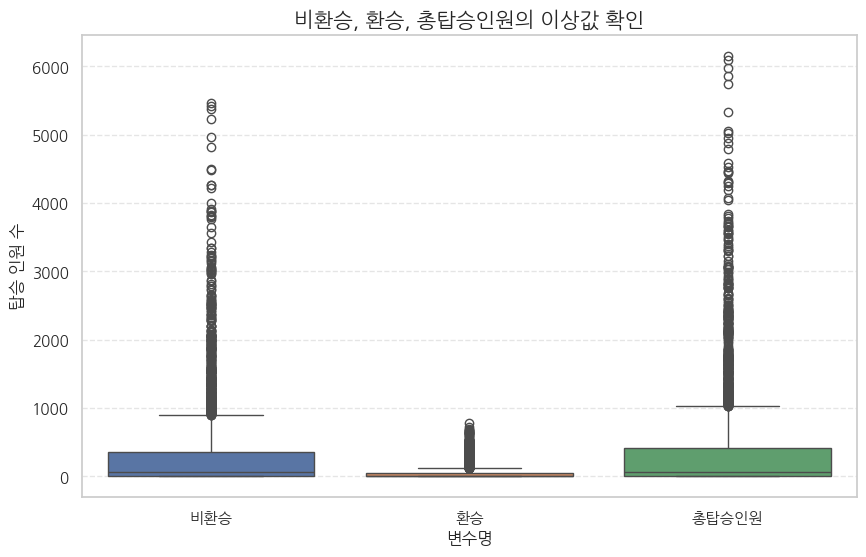

In [33]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=route_df_clean[["비환승", "환승", "총탑승인원"]]
)

plt.title("비환승, 환승, 총탑승인원의 이상값 확인", fontsize=15)
plt.xlabel("변수명", fontsize=12)
plt.ylabel("탑승 인원 수", fontsize=12)

plt.xticks(
    ticks=[0, 1, 2],
    labels=["비환승", "환승", "총탑승인원"],
    fontsize=11
)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

**3. 목표 변수 확인**

목표변수 생성 확인

In [34]:

if "총탑승인원" not in route_df_clean.columns:
    route_df_clean["총탑승인원"] = route_df_clean["비환승"] + route_df_clean["환승"]

if "환승비율" not in route_df_clean.columns:
    route_df_clean["환승비율"] = np.where(
        route_df_clean["총탑승인원"] == 0,
        0,
        route_df_clean["환승"] / route_df_clean["총탑승인원"]
    )

high_demand_threshold = route_df_clean["총탑승인원"].quantile(0.70)

route_df_clean["고수요여부"] = np.where(
    route_df_clean["총탑승인원"] >= high_demand_threshold,
    "고수요",
    "일반수요"
)

print("고수요 기준값:", high_demand_threshold)

display(route_df_clean[["노선번호", "시간대", "비환승", "환승", "총탑승인원", "환승비율", "고수요여부"]].head(5000))

고수요 기준값: 280.5


,노선번호,시간대,비환승,환승,총탑승인원,환승비율,고수요여부
0,10,00:00~00:59,0,0,0,0.000000,일반수요
1,10,01:00~01:59,0,0,0,0.000000,일반수요
2,10,02:00~02:59,0,0,0,0.000000,일반수요
3,10,03:00~03:59,0,0,0,0.000000,일반수요
4,10,04:00~04:59,0,0,0,0.000000,일반수요
...,...,...,...,...,...,...,...
3451,6000,19:00~19:59,1012,96,1108,0.086643,고수요
3452,6000,20:00~20:59,1018,99,1117,0.088630,고수요
3453,6000,21:00~21:59,898,72,970,0.074227,고수요
3454,6000,22:00~22:59,741,39,780,0.050000,고수요


회귀 문제 : 총 탑승인원 히스토그램

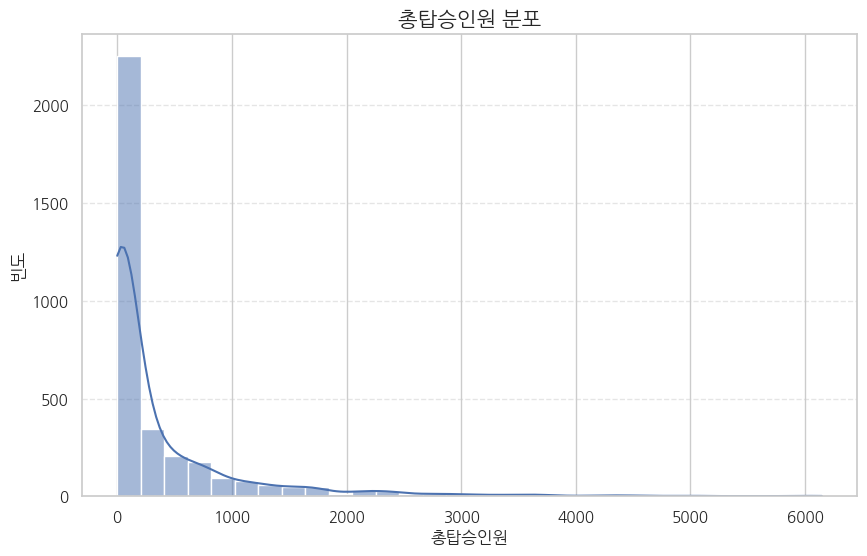

In [35]:

plt.figure(figsize=(10, 6))

sns.histplot(
    route_df_clean["총탑승인원"],
    bins=30,
    kde=True
)

plt.title("총탑승인원 분포", fontsize=15)
plt.xlabel("총탑승인원", fontsize=12)
plt.ylabel("빈도", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

총 탑승 인원 기초 통계량 확인

In [36]:

print("===== 총탑승인원 기초통계량 =====")
display(route_df_clean["총탑승인원"].describe())

===== 총탑승인원 기초통계량 =====


,총탑승인원
count,3456.000000
mean,372.763310
std,713.886557
min,0.000000
25%,0.000000
50%,68.500000
75%,409.000000
max,6145.000000


분류 문제: 고수요 여부 빈도 막대 그래프

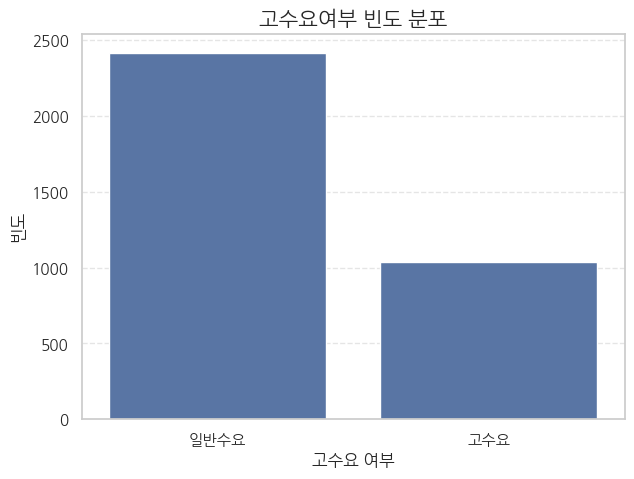

In [37]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=route_df_clean,
    x="고수요여부",
    order=["일반수요", "고수요"]
)

plt.title("고수요여부 빈도 분포", fontsize=15)
plt.xlabel("고수요 여부", fontsize=12)
plt.ylabel("빈도", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

고수요 여부 비율 확인

In [38]:

class_count = route_df_clean["고수요여부"].value_counts()
class_ratio = route_df_clean["고수요여부"].value_counts(normalize=True) * 100

class_table = pd.DataFrame({
    "빈도": class_count,
    "비율(%)": class_ratio.round(2)
})

print("===== 고수요여부 빈도 및 비율 =====")
display(class_table)

===== 고수요여부 빈도 및 비율 =====


,빈도,비율(%)
고수요여부,,
일반수요,2419,69.99
고수요,1037,30.01


클래스 불균형 여부 확인

In [39]:

major_class_ratio = class_ratio.max()
minor_class_ratio = class_ratio.min()

print("가장 많은 클래스 비율:", round(major_class_ratio, 2), "%")
print("가장 적은 클래스 비율:", round(minor_class_ratio, 2), "%")

if minor_class_ratio < 20:
    print("클래스 불균형이 다소 존재할 수 있음")
else:
    print("심각한 클래스 불균형은 아닌 것으로 판단됨")

가장 많은 클래스 비율: 69.99 %
가장 적은 클래스 비율: 30.01 %
심각한 클래스 불균형은 아닌 것으로 판단됨


**4. 설명변수 분포 시각화**

수치형 설명변수 히스토그램 : 비환승

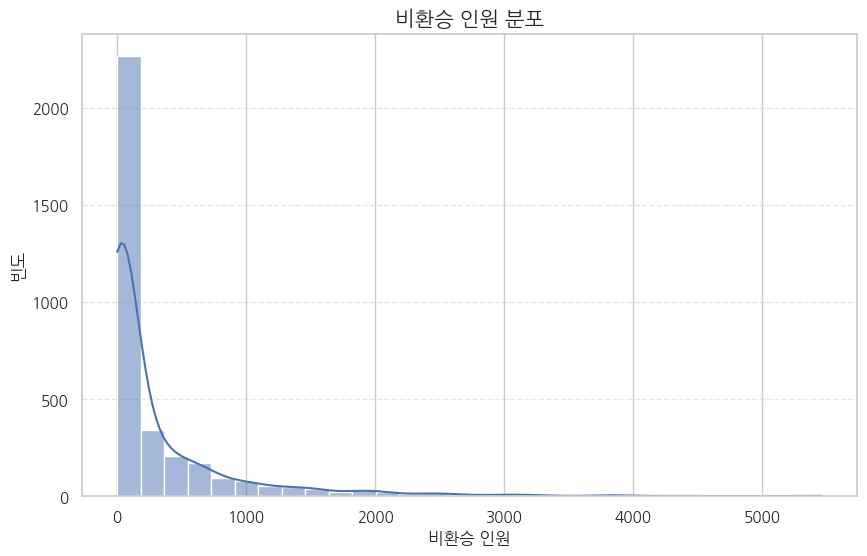

In [40]:

plt.figure(figsize=(10, 6))

sns.histplot(
    route_df_clean["비환승"],
    bins=30,
    kde=True
)

plt.title("비환승 인원 분포", fontsize=15)
plt.xlabel("비환승 인원", fontsize=12)
plt.ylabel("빈도", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

수치형 설명변수 히스토그램 : 환승

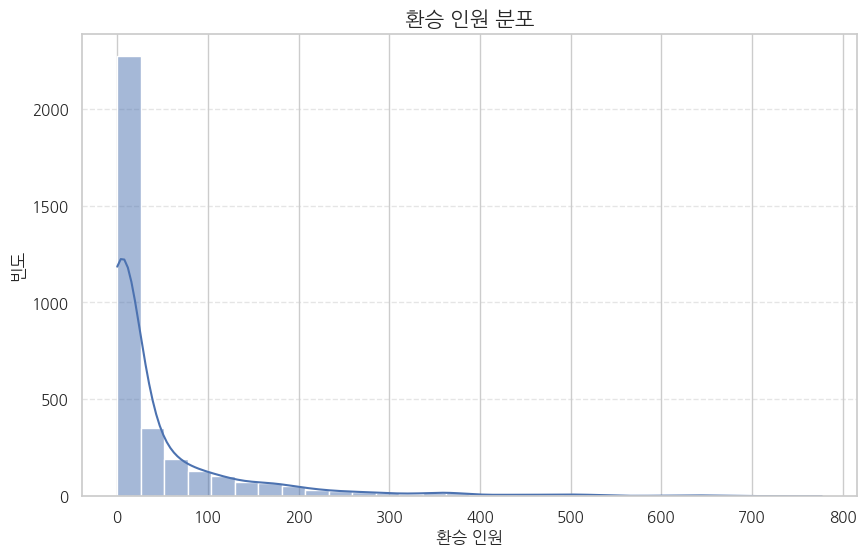

In [41]:

plt.figure(figsize=(10, 6))

sns.histplot(
    route_df_clean["환승"],
    bins=30,
    kde=True
)

plt.title("환승 인원 분포", fontsize=15)
plt.xlabel("환승 인원", fontsize=12)
plt.ylabel("빈도", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

수치형 설명변수 히스토그램: 환승 비율

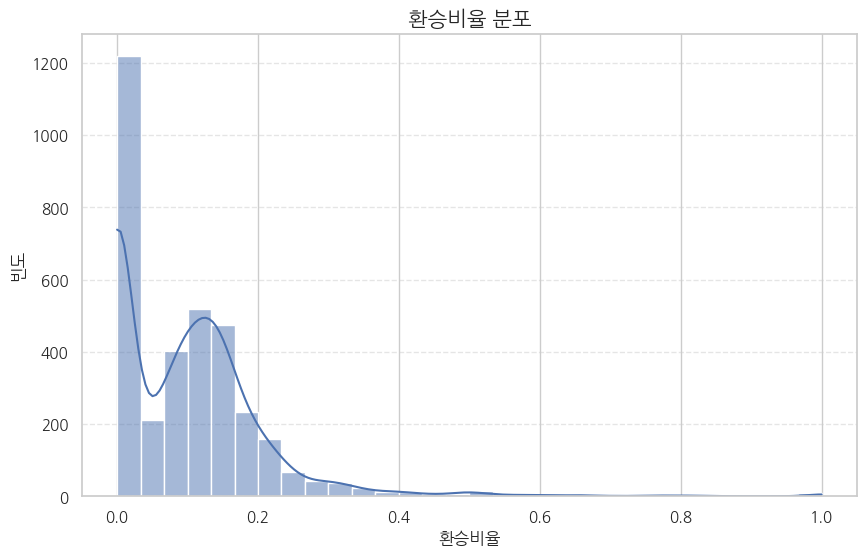

In [42]:

plt.figure(figsize=(10, 6))

sns.histplot(
    route_df_clean["환승비율"],
    bins=30,
    kde=True
)

plt.title("환승비율 분포", fontsize=15)
plt.xlabel("환승비율", fontsize=12)
plt.ylabel("빈도", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

범주형 설명변수: 시간대별 관측값 수

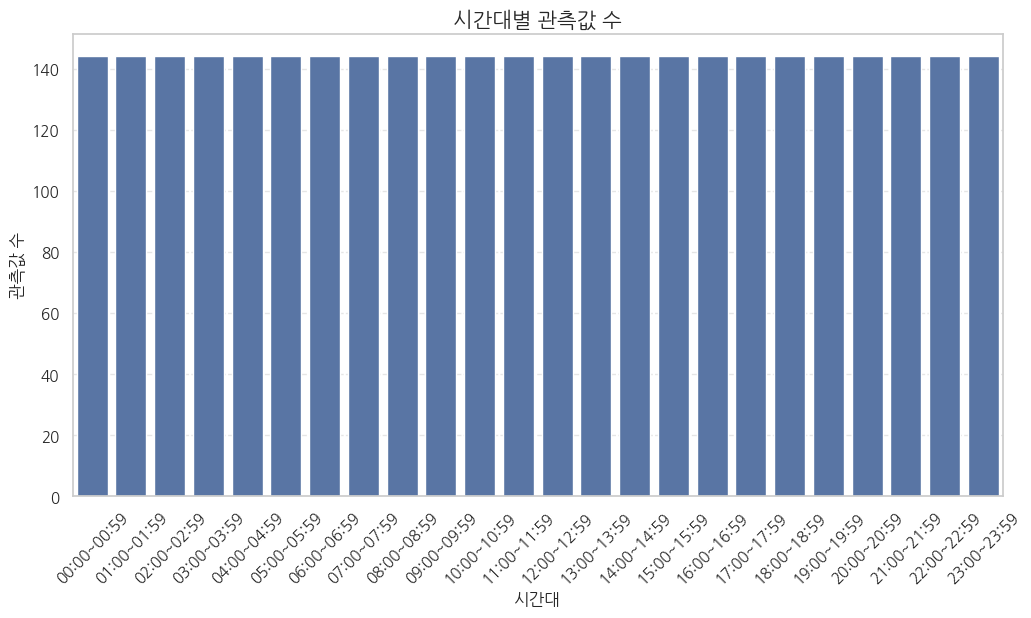

In [43]:

plt.figure(figsize=(12, 6))

sns.countplot(
    data=route_df_clean,
    x="시간대",
    order=sorted(route_df_clean["시간대"].unique())
)

plt.title("시간대별 관측값 수", fontsize=15)
plt.xlabel("시간대", fontsize=12)
plt.ylabel("관측값 수", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

목표 변수와의 관계: 시간대별 평균 총 탑승 인원

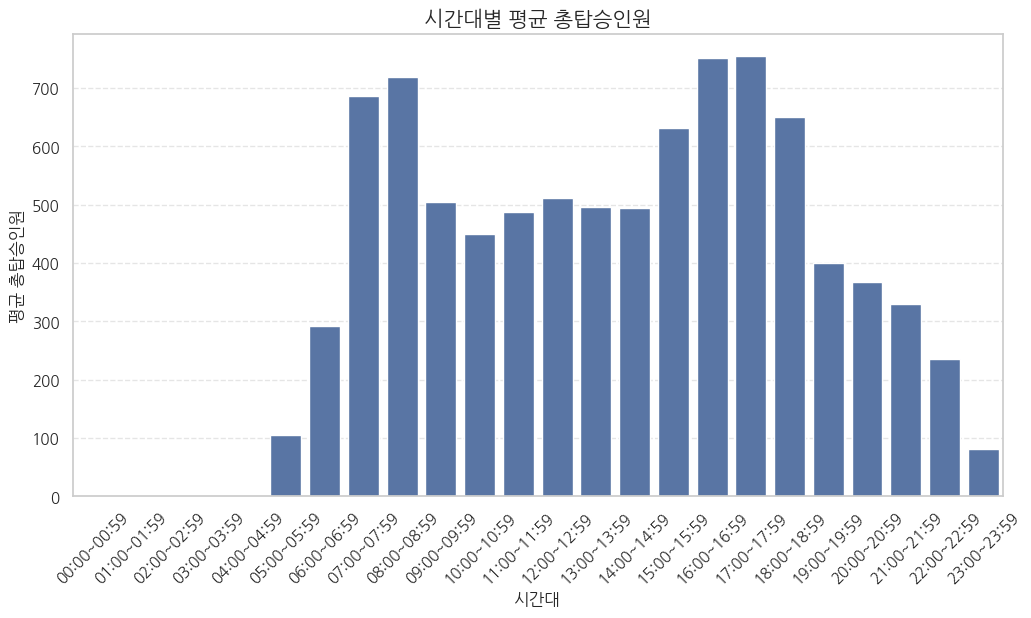

,시간대,총탑승인원
0,00:00~00:59,1.187500
1,01:00~01:59,0.000000
2,02:00~02:59,0.000000
3,03:00~03:59,0.000000
4,04:00~04:59,0.423611
5,05:00~05:59,105.618056
6,06:00~06:59,291.576389
7,07:00~07:59,686.236111
8,08:00~08:59,718.861111
9,09:00~09:59,504.277778


In [44]:

time_avg = route_df_clean.groupby("시간대")["총탑승인원"].mean().reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=time_avg,
    x="시간대",
    y="총탑승인원",
    order=sorted(route_df_clean["시간대"].unique())
)

plt.title("시간대별 평균 총탑승인원", fontsize=15)
plt.xlabel("시간대", fontsize=12)
plt.ylabel("평균 총탑승인원", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

display(time_avg)

목표변수와의 관계 : 노선별 총탑승인원 상위 10개

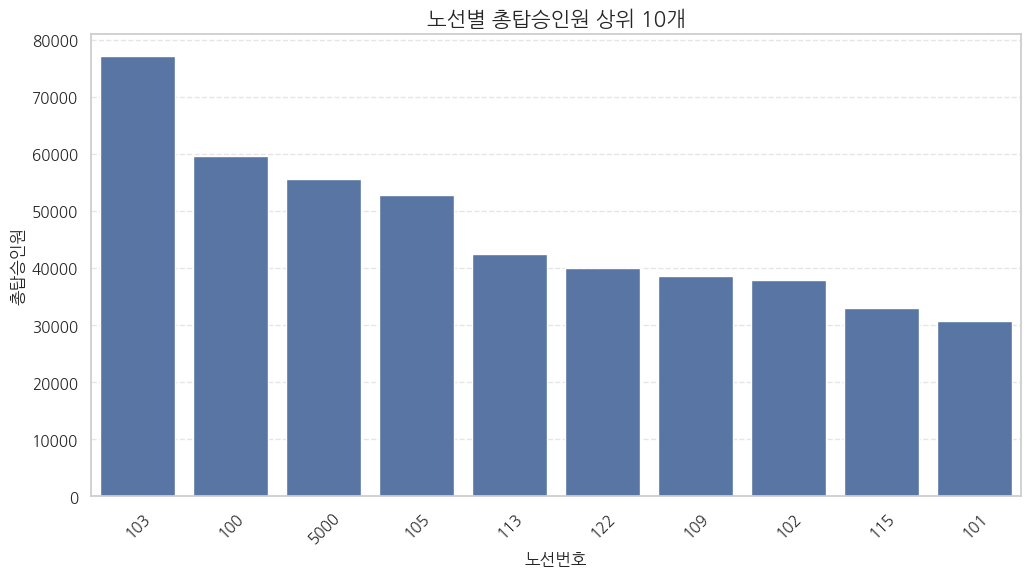

,노선번호,총탑승인원
0,103,77115
1,100,59701
2,5000,55588
3,105,52836
4,113,42502
5,122,40003
6,109,38700
7,102,37924
8,115,32957
9,101,30681


In [45]:

route_top10 = (
    route_df_clean.groupby("노선번호")["총탑승인원"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=route_top10,
    x="노선번호",
    y="총탑승인원"
)

plt.title("노선별 총탑승인원 상위 10개", fontsize=15)
plt.xlabel("노선번호", fontsize=12)
plt.ylabel("총탑승인원", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

display(route_top10)

목표변수와의 관계: 환승인원과 총 탑승인원 산점도

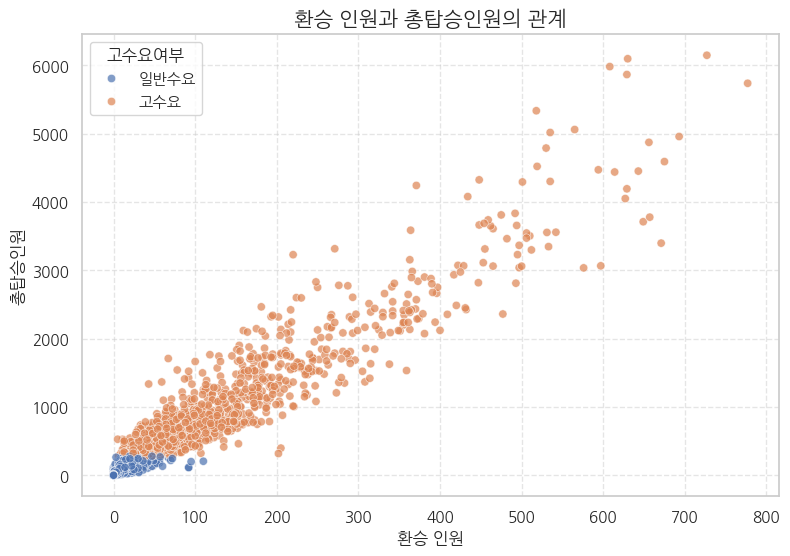

In [46]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=route_df_clean,
    x="환승",
    y="총탑승인원",
    hue="고수요여부",
    alpha=0.7
)

plt.title("환승 인원과 총탑승인원의 관계", fontsize=15)
plt.xlabel("환승 인원", fontsize=12)
plt.ylabel("총탑승인원", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

목표변수와의 관계: 비환승 인원과 총탑승 인원 산점도

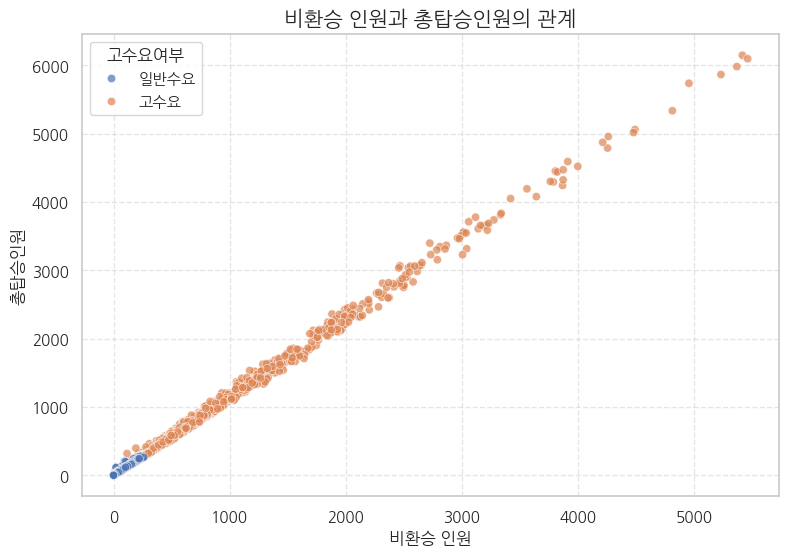

In [47]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=route_df_clean,
    x="비환승",
    y="총탑승인원",
    hue="고수요여부",
    alpha=0.7
)

plt.title("비환승 인원과 총탑승인원의 관계", fontsize=15)
plt.xlabel("비환승 인원", fontsize=12)
plt.ylabel("총탑승인원", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

**5. 상관관계 분석**

상관관계 계산

In [48]:

numeric_cols = ["비환승", "환승", "총탑승인원", "환승비율"]

corr_matrix = route_df_clean[numeric_cols].corr()

print("===== 수치형 변수 간 상관관계 =====")
display(corr_matrix)

===== 수치형 변수 간 상관관계 =====


,비환승,환승,총탑승인원,환승비율
비환승,1.000000,0.950406,0.999127,0.134868
환승,0.950406,1.000000,0.962568,0.218600
총탑승인원,0.999127,0.962568,1.000000,0.146895
환승비율,0.134868,0.218600,0.146895,1.000000


히트맵으로 상관관계 시각화

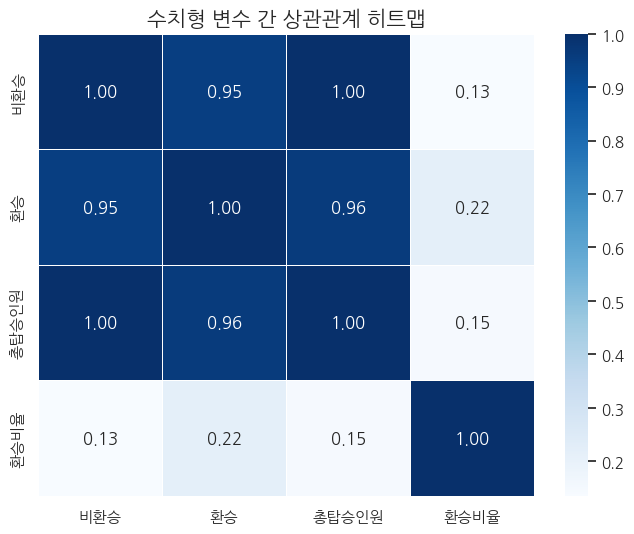

In [49]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("수치형 변수 간 상관관계 히트맵", fontsize=15)
plt.show()

목표변수와 상관관계가 높은 변수 상위 5개

In [50]:

target_corr = corr_matrix["총탑승인원"].drop("총탑승인원")

target_corr_sorted = target_corr.abs().sort_values(ascending=False)

print("===== 총탑승인원과 상관관계가 높은 변수 =====")
display(target_corr_sorted)

===== 총탑승인원과 상관관계가 높은 변수 =====


,총탑승인원
비환승,0.999127
환승,0.962568
환승비율,0.146895


상관계수 해석 기준

In [51]:

print("""
상관계수 해석 기준:
- 1에 가까울수록 강한 양의 상관관계
- -1에 가까울수록 강한 음의 상관관계
- 0에 가까울수록 선형 관계가 약함

일반적인 해석:
0.7 이상  : 강한 양의 상관관계
0.3~0.7  : 보통 수준의 양의 상관관계
0~0.3    : 약한 양의 상관관계
-0.3~0   : 약한 음의 상관관계
-0.7~-0.3: 보통 수준의 음의 상관관계
-1~-0.7  : 강한 음의 상관관계
""")


상관계수 해석 기준:
- 1에 가까울수록 강한 양의 상관관계
- -1에 가까울수록 강한 음의 상관관계
- 0에 가까울수록 선형 관계가 약함

일반적인 해석:
0.7 이상  : 강한 양의 상관관계
0.3~0.7  : 보통 수준의 양의 상관관계
0~0.3    : 약한 양의 상관관계
-0.3~0   : 약한 음의 상관관계
-0.7~-0.3: 보통 수준의 음의 상관관계
-1~-0.7  : 강한 음의 상관관계

